In [1]:
import os
import time
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import cumulative_trapezoid
import scipy.sparse as sp
import scipy.sparse.linalg as spla

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

from numpy.polynomial.chebyshev import chebval
import json

# =========================
def set_seed(seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    rng = np.random.default_rng(seed)

    return rng

rng = set_seed(2026)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device =", device)

os.makedirs("figs0529", exist_ok=True)

device = cuda


In [21]:
def set_size(width, fraction=1, subplots=(1, 1), height_add=0):
    """Set figure dimensions to avoid scaling in LaTeX.

    Parameters
    ----------
    width: float or string
            Document width in points, or string of predined document type
    fraction: float, optional
            Fraction of the width which you wish the figure to occupy
    subplots: array-like, optional
            The number of rows and columns of subplots.
    Returns
    -------
    fig_dim: tuple
            Dimensions of figure in inches
    """
    if width == 'thesis':
        width_pt = 426.79135
    elif width == 'beamer':
        width_pt = 307.28987
    else:
        width_pt = width

    # Width of figure (in pts)
    fig_width_pt = width_pt * fraction
    # Convert from pt to inches
    inches_per_pt = 1 / 72.27

    # Golden ratio to set aesthetic figure height
    #golden_ratio = (5**.5 - 1) / 2
    golden_ratio = 0.28

    
    fig_width_in = fig_width_pt * inches_per_pt
    fig_height_in = height_add + fig_width_in * golden_ratio * (subplots[0] / subplots[1])

    return (fig_width_in, fig_height_in)

tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    "font.family": "times",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 14,
    "font.size": 14,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
}

plt.rcParams.update(tex_fonts)
plt.rcParams["axes.unicode_minus"] = False



def style_3d_axes(ax3d):
    for axis in [ax3d.xaxis, ax3d.yaxis, ax3d.zaxis]:
        axis._axinfo['axisline']['linewidth'] = 1
        axis._axinfo['axisline']['color'] = "black"
        axis._axinfo['grid']['linewidth'] = 0.2
        axis._axinfo['grid']['linestyle'] = "--"
        axis._axinfo['grid']['color'] = "#d1d1d1"
    # 纯白背景
    ax3d.xaxis.set_pane_color((1.0, 1.0, 1.0, 1.0))
    ax3d.yaxis.set_pane_color((1.0, 1.0, 1.0, 1.0))
    ax3d.zaxis.set_pane_color((1.0, 1.0, 1.0, 1.0))


def plot_3d_response_draw_style(
    u_data,
    spatial,
    temporal,
    zlabel=r"$u$",
    title=None,
    filename=None,
    rstride=30,
    cstride=4,
    figsize=None,
    zlim=None,
):
    """
    Plot u(x,t) in the same 3D style as draw.ipynb.

    u_data:
        shape [nt, Nx]
    spatial:
        shape [Nx]
    temporal:
        shape [nt]
    """

    meshx, mesht = np.meshgrid(spatial, temporal)

    if figsize is None:
        figsize = set_size(516 * 3, fraction=0.99, subplots=(1, 1), height_add=0.1)

    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111, projection="3d", computed_zorder=False)

    ax.plot_surface(
        meshx,
        mesht,
        u_data,
        edgecolor="black",
        lw=0.2,
        rstride=rstride,
        cstride=cstride,
        alpha=1,
        color="white",
        shade=False,
        rasterized=False,
    )

    # Right boundary trajectory x=1
    x_right = np.ones_like(temporal)
    vals_right = u_data[:, -1]

    ax.plot(
        x_right,
        temporal,
        vals_right,
        color="red",
        lw=1.3,
        antialiased=False,
    )

    style_3d_axes(ax)

    ax.view_init(10, 15)
    if zlim is not None:
        ax.set_zlim(zlim)
        
    ax.set_xlabel("x")
    ax.set_ylabel(r"$t$")
    ax.set_zlabel(zlabel)

    ax.set_xticks([0, 0.5, 1])
    ax.zaxis.set_rotate_label(False)
    ax.zaxis.label.set_rotation(90)
    # ax.zaxis.get_offset_text().set_rotation(0)
    # ax.zaxis.get_offset_text().set_horizontalalignment("left")
    # ax.zaxis.get_offset_text().set_verticalalignment("bottom")

    if title is not None:
        ax.set_title(title)

    plt.tight_layout()

    if filename is not None:
        fig.savefig(filename, dpi=300, bbox_inches="tight", pad_inches=0.06)

    plt.show()

    return fig, ax


def plot_2d_draw_style(
    x,
    ys,
    labels=None,
    linestyles=None,
    xlabel="time",
    ylabel=None,
    filename=None,
    grid=True,
):
    """
    2D line plot in the same style as draw.ipynb.
    """

    plt.figure(figsize=(1000 / 300, 618 / 300), dpi=300)

    if not isinstance(ys, (list, tuple)):
        ys = [ys]

    if labels is None:
        labels = [None] * len(ys)

    if linestyles is None:
        linestyles = ["-"] * len(ys)

    for y, label, ls in zip(ys, labels, linestyles):
        plt.plot(
            x,
            y,
            ls,
            label=label,
            linewidth=1.5,
        )

    plt.xlabel(xlabel, fontsize=8)

    if ylabel is not None:
        plt.ylabel(ylabel, fontsize=8)

    if any(label is not None for label in labels):
        plt.legend(fontsize=10)

    if grid:
        plt.grid(True)

    plt.tight_layout()

    if filename is not None:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()

from cmath import rect

from cmath import rect

from mpl_toolkits.axes_grid1.inset_locator import Rectangle, inset_axes, mark_inset
import numpy as np
import matplotlib.pyplot as plt


def plot_2d_draw_style_with_inset(
    x,
    ys,
    labels=None,
    linestyles=None,
    ylim=None,      
    xlabel="time",
    ylabel=None,
    filename=None,
    grid=True,
    yscale="linear",
    legend_loc="best",
    legend_fontsize=6,
    zoom_xlim=None,
    zoom_ylim=None,
    inset_loc="upper right",
    inset_width="40%",
    inset_height="40%",
    inset_bbox=None,
):
    """
    2D line plot with an inset zoom region.

    zoom_xlim:
        tuple, for example (0.05, 0.30)
    zoom_ylim:
        tuple, for example (0.8, 1.2). If None, it is determined automatically.
    """

    fig, ax = plt.subplots(figsize=(1000 / 300, 618 / 300), dpi=300)

    if not isinstance(ys, (list, tuple)):
        ys = [ys]

    n_curves = len(ys)

    if labels is None:
        labels = [None] * n_curves

    if linestyles is None:
        linestyles = ["-", "--", ":", "-."][:n_curves]

    if len(labels) != n_curves:
        raise ValueError("labels and ys must have the same length.")

    if len(linestyles) != n_curves:
        raise ValueError("linestyles and ys must have the same length.")

    # Main plot
    for y, label, ls in zip(ys, labels, linestyles):
        ax.plot(
            x,
            y,
            ls,
            label=label,
            linewidth=1.5,
        )

    ax.set_xlabel(xlabel, fontsize=9)

    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=9)
    
    if ylim is not None:
        ax.set_ylim(ylim)

    ax.set_yscale(yscale)

    if grid:
        ax.grid(True)

    if any(label is not None for label in labels):
        ax.legend(fontsize=legend_fontsize, loc=legend_loc)
    
    ax.tick_params(axis="both", labelsize=8)

    # Inset zoom
    if zoom_xlim is not None:
        if inset_bbox is not None:
            axins = ax.inset_axes(inset_bbox)
        else:
            axins = inset_axes(ax, width=inset_width,height=inset_height,loc=inset_loc,borderpad=1.0,)

        for y, label, ls in zip(ys, labels, linestyles):
            axins.plot(
                x,
                y,
                ls,
                linewidth=1.2,
            )

        axins.set_xlim(zoom_xlim)

        if zoom_ylim is None:
            mask = (x >= zoom_xlim[0]) & (x <= zoom_xlim[1])

            y_min = min(np.min(np.asarray(y)[mask]) for y in ys)
            y_max = max(np.max(np.asarray(y)[mask]) for y in ys)

            margin = 0.08 * (y_max - y_min + 1e-12)
            zoom_ylim = (y_min - margin, y_max + margin)

        axins.set_ylim(zoom_ylim)

        axins.tick_params(axis="both", labelsize=7)

        if grid:
            axins.grid(True)

        # Draw rectangle and connectors
        # mark_inset(
        #     ax,
        #     axins,
        #     loc1=mark_loc1,
        #     loc2=mark_loc2,
        #     fc="none",
        #     ec="0.3",
        #     linewidth=0.8,
        # )
        # Draw only the zoom rectangle on the main axes, without connector lines.
        rect = Rectangle((zoom_xlim[0], zoom_ylim[0]),
                         zoom_xlim[1] - zoom_xlim[0],
                         zoom_ylim[1] - zoom_ylim[0],
                         fill=False, edgecolor="0.3", linewidth=0.8, linestyle="--",)

    ax.add_patch(rect)

    plt.tight_layout()

    if filename is not None:
        fig.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()

    return fig, ax

In [3]:
# Part1 Define reaction coefficients, integral weights, and initial values.

def make_lam_fn(beta):
    """
    lambda(x)=50*cos(beta*arccos(x)).
    x should be in [0,1].
    """
    def lam(x):
        x = np.asarray(x)
        x_clip = np.clip(x, 0.0, 1.0)
        return 50.0 * np.cos(beta * np.arccos(x_clip))
    return lam


def get_simpson_coeff(spatial):
    """
    Simpson quadrature weights on [0,1].
    If the number of intervals is not even, use trapezoidal weights.
    """
    spatial = np.asarray(spatial, dtype=float)
    N = len(spatial)
    dx = spatial[1] - spatial[0]

    if (N - 1) % 2 != 0:
        w = np.ones(N) * dx
        w[0] *= 0.5
        w[-1] *= 0.5
        return w

    w = np.ones(N)
    w[1:-1:2] = 4.0
    w[2:-1:2] = 2.0
    w *= dx / 3.0
    return w


def make_initial_profile(
    spatial,
    init_type="sin",
    amp=1.0,
    rng=None,
    n_modes=8,
    decay_power=2.0,
    normalize=True,
):
    """
    Generate an initial state satisfying u(0)=u(1)=0.

    Parameters
    ----------
    spatial : array_like
        Spatial grid on [0, 1].
    init_type : str
        Type of initial condition:
        - "zero"
        - "sin"
        - "sin2"
        - "mixed"
        - "random_sine"
        - "cheb_single"
        - "cheb_random"
    amp : float
        Amplitude of the initial profile.
    rng : np.random.Generator or None
        Random number generator. If None, a default generator is used.
    n_modes : int
        Number of modes used in random expansions.
    decay_power : float
        Decay rate for high-order coefficients.
    normalize : bool
        Whether to normalize the generated profile before multiplying by amp.

    Returns
    -------
    u0 : ndarray
        Initial profile satisfying u0(0)=u0(1)=0.
    """

    x = np.asarray(spatial, dtype=float)

    if rng is None:
        rng = np.random.default_rng()

    if init_type == "zero":
        profile = np.zeros_like(x)

    elif init_type == "sin":
        profile = np.sin(np.pi * x)

    elif init_type == "sin2":
        profile = np.sin(2.0 * np.pi * x)

    elif init_type == "mixed":
        profile = (
            0.8 * np.sin(np.pi * x)
            + 0.2 * np.sin(2.0 * np.pi * x)
        )

    elif init_type == "random_sine":
        profile = np.zeros_like(x)

        for j in range(1, n_modes + 1):
            coeff = rng.uniform(-1.0, 1.0) / (j ** decay_power)
            profile += coeff * np.sin(j * np.pi * x)

    elif init_type == "cheb_single":
        beta0 = rng.uniform(1.0, 10.0)
        x_clip = np.clip(x, 0.0, 1.0)

        profile = np.cos(beta0 * np.arccos(x_clip))

        # Enforce u0(0)=u0(1)=0.
        profile = x * (1.0 - x) * profile

    elif init_type == "cheb_random":
        xi = 2.0 * x - 1.0

        coeffs = rng.uniform(-1.0, 1.0, size=n_modes + 1)

        decay = np.array([
            (j + 1) ** (-decay_power)
            for j in range(n_modes + 1)
        ])

        coeffs = coeffs * decay

        profile = chebval(xi, coeffs)

        # Enforce u0(0)=u0(1)=0.
        profile = x * (1.0 - x) * profile

    else:
        raise ValueError(f"Unknown init_type: {init_type}")

    if normalize:
        max_abs = np.max(np.abs(profile))
        if max_abs > 1e-12:
            profile = profile / max_abs

    return amp * profile

# Part2 Define functions to solve the controller kernel k(x,y) and observer kernel g(x,y) using Goursat marching in characteristic coordinates.
def solve_k(lambda_func, spatial, return_Kxy=False, check=False):
    """
    Solve the controller kernel k(x,y) on 0 <= y <= x <= 1.

    Kernel equation:
        k_xx(x,y) - k_yy(x,y) = lambda(y) k(x,y)

    Boundary conditions:
        k(x,0) = 0
        k(x,x) = -1/2 int_0^x lambda(s) ds

    Characteristic coordinates:
        r = x + y
        s = x - y
    """

    spatial = np.asarray(spatial, dtype=float)
    N = len(spatial)
    dx = spatial[1] - spatial[0]

    if not np.allclose(np.diff(spatial), dx):
        raise ValueError("spatial must be a uniform grid.")

    Ns = N
    Nr = 2 * N - 1

    s_grid = np.linspace(0.0, 1.0, Ns)
    r_grid = np.linspace(0.0, 2.0, Nr)
    h = s_grid[1] - s_grid[0]

    ii = np.arange(Nr)[:, None]
    jj = np.arange(Ns)[None, :]
    valid = (ii >= jj) & (ii <= (Nr - 1 - jj))

    Krs = np.full((Nr, Ns), np.nan, dtype=np.float64)

    # Boundary s=0: k(x,x)
    x_int = spatial
    lam_int = np.asarray(lambda_func(x_int), dtype=np.float64)

    F = -0.5 * cumulative_trapezoid(lam_int, x_int, initial=0.0)
    Krs[:, 0] = np.interp(r_grid / 2.0, x_int, F)

    # Boundary r=s: k(x,0)=0
    for j in range(Ns):
        Krs[j, j] = 0.0

    # Goursat marching
    for i in range(Nr - 1):
        for j in range(Ns - 1):

            if not (
                valid[i, j]
                and valid[i + 1, j]
                and valid[i, j + 1]
                and valid[i + 1, j + 1]
            ):
                continue

            if (
                np.isnan(Krs[i + 1, j])
                or np.isnan(Krs[i, j + 1])
                or np.isnan(Krs[i, j])
            ):
                continue

            r_c = 0.5 * (r_grid[i] + r_grid[i + 1])
            s_c = 0.5 * (s_grid[j] + s_grid[j + 1])
            y_c = 0.5 * (r_c - s_c)

            a_c = 0.25 * float(lambda_func(y_c))
            q = (h * h * a_c) / 4.0

            SW = Krs[i, j]
            SE = Krs[i + 1, j]
            NW = Krs[i, j + 1]

            # Semi-implicit midpoint update for NE
            # NE - SE - NW + SW = h^2 a_c * (SW+SE+NW+NE)/4
            denom = 1.0 - q
            NE = (SE + NW - SW + q * (SW + SE + NW)) / denom

            Krs[i + 1, j + 1] = NE

    # Extract k(1,y)
    r_index = np.arange(N - 1, 2 * N - 1)
    s_index = np.arange(N - 1, -1, -1)
    Kxy_gain = Krs[r_index, s_index].copy()

    Kxy = None
    if return_Kxy or check:
        Kxy = np.full((N, N), np.nan, dtype=np.float64)
        for i in range(N):
            for j in range(i + 1):
                r_idx = i + j
                s_idx = i - j
                Kxy[i, j] = Krs[r_idx, s_idx]

    if check:
        diag_err = np.nanmax(np.abs(np.diag(Kxy) - F))
        left_boundary_err = np.nanmax(np.abs(Kxy[:, 0]))

        print("solve_k consistency check:")
        print(f"  max diagonal error = {diag_err:.3e}")
        print(f"  max k(x,0) error   = {left_boundary_err:.3e}")

    if return_Kxy:
        return Krs, Kxy, Kxy_gain

    return Krs, Kxy_gain


def solve_g(lambda_func, spatial, check=False):
    """
    Directly solve the observer kernel g(x,y) on 0 <= y <= x <= 1.

    Observer kernel equation:
        g_xx(x,y) - g_yy(x,y) = -lambda(x) g(x,y)

    Boundary conditions:
        g(1,y) = 0
        g(x,x) = -1/2 int_x^1 lambda(s) ds

    Observer gain:
        g1(x) = -g(x,0)

    Return:
        Gxy     : lower-triangular array, Gxy[i,j]=g(x_i,y_j)
        g1_gain : array, g1_gain[i]=g1(x_i)
    """

    spatial = np.asarray(spatial, dtype=float)
    N = len(spatial)
    dx = spatial[1] - spatial[0]

    if not np.allclose(np.diff(spatial), dx):
        raise ValueError("spatial must be a uniform grid.")

    Ns = N
    Nr = 2 * N - 1

    s_grid = np.linspace(0.0, 1.0, Ns)
    r_grid = np.linspace(0.0, 2.0, Nr)
    h = s_grid[1] - s_grid[0]

    ii = np.arange(Nr)[:, None]
    jj = np.arange(Ns)[None, :]
    valid = (ii >= jj) & (ii <= (Nr - 1 - jj))

    Grs = np.full((Nr, Ns), np.nan, dtype=np.float64)

    # Boundary s=0: g(x,x) = -1/2 int_x^1 lambda(z) dz
    x_int = spatial
    lam_int = np.asarray(lambda_func(x_int), dtype=np.float64)

    F = cumulative_trapezoid(lam_int, x_int, initial=0.0)
    F_total = F[-1]

    x_on_r = r_grid / 2.0
    F_on_r = np.interp(x_on_r, x_int, F)

    Grs[:, 0] = -0.5 * (F_total - F_on_r)

    # Boundary x=1: r+s=2
    for j in range(Ns):
        i_right = Nr - 1 - j
        Grs[i_right, j] = 0.0

    # March from right to left
    for j in range(Ns - 1):

        i_right_next = Nr - 1 - (j + 1)

        for i in range(i_right_next - 1, j, -1):

            if not (
                valid[i, j]
                and valid[i + 1, j]
                and valid[i, j + 1]
                and valid[i + 1, j + 1]
            ):
                continue

            if (
                np.isnan(Grs[i + 1, j + 1])
                or np.isnan(Grs[i + 1, j])
                or np.isnan(Grs[i, j])
            ):
                continue

            r_c = 0.5 * (r_grid[i] + r_grid[i + 1])
            s_c = 0.5 * (s_grid[j] + s_grid[j + 1])
            x_c = 0.5 * (r_c + s_c)

            a_c = -0.25 * float(lambda_func(x_c))
            q = (h * h * a_c) / 4.0

            SW = Grs[i, j]
            SE = Grs[i + 1, j]
            NE = Grs[i + 1, j + 1]

            # Solve for NW:
            # NE - SE - NW + SW = h^2 a_c * (SW+SE+NW+NE)/4
            NW_tilde = NE - SE + SW
            NW = (NW_tilde - q * (SW + SE + NE)) / (1.0 + q)

            Grs[i, j + 1] = NW

    # Convert to g(x,y)
    Gxy = np.full((N, N), np.nan, dtype=np.float64)

    for i in range(N):
        for j in range(i + 1):
            r_idx = i + j
            s_idx = i - j
            Gxy[i, j] = Grs[r_idx, s_idx]

    # Observer gain
    g1_gain = -Gxy[:, 0].copy()

    if check:
        diag_target = -0.5 * (F_total - F)
        diag_err = np.nanmax(np.abs(np.diag(Gxy) - diag_target))
        right_err = np.nanmax(np.abs(Gxy[-1, :]))

        print("solve_g consistency check:")
        print(f"  max diagonal error = {diag_err:.3e}")
        print(f"  max g(1,y) error   = {right_err:.3e}")

    return Gxy, g1_gain


# Part3 Build Crank--Nicolson matrices for the interior nodes, and compute the left boundary flux using second-order finite difference.
def build_interior_CN_mats(spatial, dt, lam_profile):
    """
    Interior-node Crank--Nicolson matrices for
        v_t = v_xx + lambda(x) v.
    Boundary values are handled separately.
    """
    spatial = np.asarray(spatial, dtype=float)
    dx = spatial[1] - spatial[0]
    Nx = len(spatial)
    n_int = Nx - 2

    lam_int = lam_profile[1:-1]

    main = -2.0 / dx**2 + lam_int
    off = np.ones(n_int - 1) / dx**2

    A = sp.diags(
        [off, main, off],
        offsets=[-1, 0, 1],
        shape=(n_int, n_int),
        format="csr"
    )

    I = sp.eye(n_int, format="csr")

    M_minus = I - 0.5 * dt * A
    M_plus = I + 0.5 * dt * A

    return M_minus, M_plus


def left_flux_second_order(v, dx):
    """
    u_x(0,t) ≈ (-3u(0,t)+4u(dx,t)-u(2dx,t))/(2dx).
    """
    return (-3.0 * v[0] + 4.0 * v[1] - v[2]) / (2.0 * dx)



In [4]:
def build_CN_operators_outputfeedback(spatial, dt, lam, K_vals, p1_vals):
    """
    输出反馈闭环的离散算子:
        u_t     = u_xx + lam(x) u
        u(0,t)  = 0
        u(1,t)  = U(t)

        uhat_t  = uhat_xx + lam(x) uhat
                  + p1(x)[ u_x(1,t) - uhat_x(1,t) ]
        uhat(0,t)=0
        uhat(1,t)=U(t)

        U(t) = ∫_0^1 k(1,x) uhat(x,t) dx

    状态向量 z = [u; uhat] ∈ R^{2*Nx}，返回稀疏矩阵 A, B，
    满足一步格式:  A z^{n+1} = B z^n
    """

    dx = spatial[1] - spatial[0]
    Nx = len(spatial)

    lam     = np.asarray(lam).reshape(-1)
    K_vals  = np.asarray(K_vals).reshape(-1)
    p1_vals = np.asarray(p1_vals).reshape(-1)

    assert lam.shape[0]     == Nx
    assert K_vals.shape[0]  == Nx
    assert p1_vals.shape[0] == Nx

    # ----- CN 系数 -----
    alpha = dt / (2.0 * dx**2)
    beta  = lam * dt / 2.0

    # ================== A1: plant 的 A (CN) ==================
    A1_main = np.concatenate([[1.0],
                              np.ones(Nx-2) + 2.0*alpha*np.ones(Nx-2) - beta[1:-1],
                              [1.0]])                        # 边界 main=1
    A1_up   = np.concatenate([[0.0], -alpha*np.ones(Nx-2)])
    A1_low  = np.concatenate([-alpha*np.ones(Nx-2), [0.0]])

    A1 = diags([A1_low, A1_main, A1_up],
               offsets=[-1, 0, 1],
               shape=(Nx, Nx)).tolil()

    # ================== backstepping 卷积权重 ==================
    simpson = get_simpson_coeff(spatial)       # shape (Nx,)
    # U ≈ sum_j w_j k(1,x_j) uhat_j
    W = simpson * K_vals                       # 权重 W_j
    row_update = -W                            # u_N - sum(W * uhat) = 0

    # ================== A2: u(1)=U(t) 的代数条件 ==================
    A2 = lil_matrix((Nx, Nx))
    A2[-1, :] = row_update                     # u_N + row_update·uhat = 0

    # ================== A3: 不直接耦合 u 到 observer 边界 (留零) ==================
    A3 = lil_matrix((Nx, Nx))                  # 全 0

    # ================== A4: observer PDE 的 A ==================
    # 先放 CN 的 L 部分
    A4 = A1.copy().tolil()

    # 再加上 -p1(x)*uhat_x(1) 的 BE (全隐式) 部分
    # 使用 backward difference:
    # u_x(1) ≈ (-u_{N-2} + 4 u_{N-1} - 3 u_N) / (2 dx)
    gamma = p1_vals * dt / (2.0 * dx)          # shape (Nx,)
    gamma_col = gamma.reshape(-1, 1)

    # 仅对内部行 1..Nx-2 施加导数反馈
    A4[1:-1, -3] += -gamma_col[1:-1]
    A4[1:-1, -2] +=  4.0 * gamma_col[1:-1]
    A4[1:-1, -1] += -3.0 * gamma_col[1:-1]

    # 覆盖 observer 的最后一行为边界条件: uhat_N - sum(W * uhat) = 0
    A4[-1, :] = 0.0
    A4[-1, -1] = 1.0
    A4[-1, :] += row_update                    # 与 A2 的卷积结构一致

    A4 = A4.tocsr()

    # ================== 拼 A ==================
    A = bmat([[A1, A2],
              [A3, A4]], format='csr')

    # ================== B1: plant 的 B (CN) ==================
    B1_main = np.concatenate([[0.0],
                              np.ones(Nx-2) - 2.0*alpha*np.ones(Nx-2) + beta[1:-1],
                              [0.0]])                        # 边界行为 0
    B1_up   = np.concatenate([[0.0], alpha*np.ones(Nx-2)])
    B1_low  = np.concatenate([alpha*np.ones(Nx-2), [0.0]])

    B1 = diags([B1_low, B1_main, B1_up],
               offsets=[-1, 0, 1],
               shape=(Nx, Nx)).tolil()

    # ================== B2: 0 ==================
    B2 = lil_matrix((Nx, Nx))

    # ================== B3: +p1(x) u_x(1,t^n) 显式 ==================
    B3 = lil_matrix((Nx, Nx))
    gamma_u = p1_vals * dt / (2.0 * dx)
    gamma_u_col = gamma_u.reshape(-1, 1)

    # 同样使用 backward difference
    B3[1:-1, -3] += -gamma_u_col[1:-1]
    B3[1:-1, -2] +=  4.0 * gamma_u_col[1:-1]
    B3[1:-1, -1] += -3.0 * gamma_u_col[1:-1]

    # ================== B4: observer PDE 的 B ==================
    # 只保留 L 的 CN 显式部分; 边界行已经在 A4 中处理，因此保持 0
    B4 = B1.copy().tocsr()

    # ================== 拼 B ==================
    B = bmat([[B1, B2],
              [B3, B4]], format='csr')

    return A, B

# %% [markdown]
# ## 闭环仿真 & 数据集生成

def simulate_one_trajectory_opfk(lam_param, spatial, nt, dt):

    Nx = len(spatial)
    dx = spatial[1] - spatial[0]    
    lambda_func = make_lam_fn(lam_param)
    lam_profile = lambda_func(spatial)                  

    _, Kxy_gain = solve_k(lambda_func, spatial)
    p1_vals = -Kxy_gain

    u = np.zeros((nt, 2*Nx), dtype=np.float32)
    u[0,0:Nx] = 1.0
  
    A, B = build_CN_operators_outputfeedback(spatial, dt, lam_profile, Kxy_gain, p1_vals)

    for k in range(1, nt):
      u[k,:] = step_CN(u[k-1,:], A, B)

    # u_x0 = (u[:,1] - u[:,0]) / dx      # [nt]
    # u_x0 = (-3*u[:, 0] + 4*u[:, 1] - u[:, 2]) / (2*dx)
    u_x1 = (-u[:, Nx-3] + 4*u[:, Nx-2] - 3*u[:, Nx-1]) / (2*dx)
    U_ctrl = u[:, Nx-1]                    

    return lam_profile.astype(np.float32),  u_x1.astype(np.float32), U_ctrl.astype(np.float32)


# Part4 Define a function to simulate the output-feedback trajectory using the backstepping controller and observer. 
# Define a function to simulate the open-loop response of the PDE with zero control input.

def simulate_outputfeedback_trajectory(
    lam_param,
    spatial,
    nt,
    dt,
    u0_profile,
    check_kernel=False
):
    """
    Generate one trajectory by the classical output-feedback backstepping law.

    Return:
        lam_profile : [Nx]
        p_seq       : [nt], p(t)=u_x(0,t)
        U_seq       : [nt]
        u           : [nt,Nx]
        uhat        : [nt,Nx]
    """

    spatial = np.asarray(spatial, dtype=float)
    Nx = len(spatial)
    dx = spatial[1] - spatial[0]

    lambda_func = make_lam_fn(lam_param)
    lam_profile = np.asarray(lambda_func(spatial), dtype=np.float64)

    # Controller kernel boundary gain k(1,y)
    _, k_gain = solve_k(lambda_func, spatial)
    k_gain = np.asarray(k_gain, dtype=np.float64).reshape(-1)

    # Observer gain g1(x)=-g(x,0)
    Gxy, g1_gain = solve_g(lambda_func, spatial, check=check_kernel)
    g1_gain = np.asarray(g1_gain, dtype=np.float64).reshape(-1)

    # Quadrature weights
    wq = get_simpson_coeff(spatial).astype(np.float64)

    # Algebraic boundary control:
    # U = sum_j w_j k_j uhat_j, with uhat_N = U.
    denom = 1.0 - wq[-1] * k_gain[-1]
    if abs(denom) < 1e-10:
        raise RuntimeError("The feedback denominator is too close to zero.")

    cU = (wq[1:-1] * k_gain[1:-1]) / denom

    # Interior CN matrices
    M_minus, M_plus = build_interior_CN_mats(spatial, dt, lam_profile)
    n_int = Nx - 2

    eR = np.zeros(n_int)
    eR[-1] = 1.0

    plant_solver = spla.factorized(M_minus.tocsc())

    # Observer solver with implicit U^{n+1}=cU@uhat^{n+1}
    M_obs = M_minus.tolil()
    M_obs[-1, :] -= (dt / (2.0 * dx**2)) * cU
    obs_solver = spla.factorized(M_obs.tocsc())

    u = np.zeros((nt, Nx), dtype=np.float64)
    uhat = np.zeros((nt, Nx), dtype=np.float64)
    U = np.zeros(nt, dtype=np.float64)
    p = np.zeros(nt, dtype=np.float64)
    phat = np.zeros(nt, dtype=np.float64)

    # Initial conditions
    # u[0, :] = make_initial_profile(spatial, init_type=init_type, amp=amp)
    # u0_profile =  make_initial_profile(spatial, init_type="cheb_random", amp=amp, rng=rng, n_modes=8, decay_power=2.0, normalize=True)
    u0_profile = np.asarray(u0_profile, dtype=np.float64).reshape(-1)
    u[0, :] = u0_profile
    uhat[0, :] = 0.0

    u[0, 0] = 0.0
    uhat[0, 0] = 0.0

    U[0] = float(cU @ uhat[0, 1:-1])
    u[0, -1] = U[0]
    uhat[0, -1] = U[0]

    for n in range(nt - 1):
        u_int = u[n, 1:-1]
        uh_int = uhat[n, 1:-1]

        U_old = U[n]

        p[n] = left_flux_second_order(u[n, :], dx)
        phat[n] = left_flux_second_order(uhat[n, :], dx)

        innovation = p[n] - phat[n]

        # Observer update
        rhs_hat = (
            M_plus @ uh_int
            + (dt / (2.0 * dx**2)) * U_old * eR
            + dt * g1_gain[1:-1] * innovation
        )

        uh_new_int = obs_solver(rhs_hat)

        # New control
        U_new = float(cU @ uh_new_int)

        # Plant update
        rhs_u = (
            M_plus @ u_int
            + (dt / (2.0 * dx**2)) * (U_old + U_new) * eR
        )

        u_new_int = plant_solver(rhs_u)

        u[n + 1, 0] = 0.0
        u[n + 1, 1:-1] = u_new_int
        u[n + 1, -1] = U_new

        uhat[n + 1, 0] = 0.0
        uhat[n + 1, 1:-1] = uh_new_int
        uhat[n + 1, -1] = U_new

        U[n + 1] = U_new

    p[-1] = left_flux_second_order(u[-1, :], dx)
    phat[-1] = left_flux_second_order(uhat[-1, :], dx)

    return (
        lam_profile.astype(np.float32),
        p.astype(np.float32),
        U.astype(np.float32),
        u.astype(np.float32),
        uhat.astype(np.float32),
    )


def simulate_open_loop(
    lam_param,
    spatial,
    nt,
    dt,
    u0_profile,
    max_abs_stop=1e8,
):
    """
    Open-loop simulation of
        u_t = u_xx + lambda(x) u,
        u(0,t)=0,
        u(1,t)=0.

    Parameters
    ----------
    lam_param : float
        beta in lambda(x)=50*cos(beta*arccos(x)).
    spatial : ndarray
        Spatial grid.
    nt : int
        Number of time steps.
    dt : float
        Time step.
    u0_profile : ndarray
        Initial state profile.

    Returns
    -------
    result : dict
        Contains u, U, p, l2_norm, time.
    """

    spatial = np.asarray(spatial, dtype=float)
    Nx = len(spatial)
    dx = spatial[1] - spatial[0]

    u0_profile = np.asarray(u0_profile, dtype=np.float64).reshape(-1)

    if u0_profile.shape[0] != Nx:
        raise ValueError(
            f"u0_profile has length {u0_profile.shape[0]}, but Nx={Nx}."
        )

    lambda_func = make_lam_fn(lam_param)
    lam_profile = np.asarray(lambda_func(spatial), dtype=np.float64)

    M_minus, M_plus = build_interior_CN_mats(spatial, dt, lam_profile)

    n_int = Nx - 2
    eR = np.zeros(n_int, dtype=np.float64)
    eR[-1] = 1.0

    plant_solver = spla.factorized(M_minus.tocsc())

    u = np.zeros((nt, Nx), dtype=np.float64)
    U = np.zeros(nt, dtype=np.float64)
    p = np.zeros(nt, dtype=np.float64)

    u[0, :] = u0_profile.copy()

    # Homogeneous Dirichlet boundaries for open-loop.
    u[0, 0] = 0.0
    u[0, -1] = 0.0
    U[0] = 0.0

    stopped_early = False
    stop_step = nt - 1

    for n in range(nt - 1):
        p[n] = left_flux_second_order(u[n, :], dx)

        u_int = u[n, 1:-1]

        # Open-loop boundary: U_old = U_new = 0.
        U_old = 0.0
        U_new = 0.0

        rhs_u = (
            M_plus @ u_int
            + (dt / (2.0 * dx**2)) * (U_old + U_new) * eR
        )

        u_new_int = plant_solver(rhs_u)

        u[n + 1, 0] = 0.0
        u[n + 1, 1:-1] = u_new_int
        u[n + 1, -1] = 0.0
        U[n + 1] = 0.0

        if (
            np.any(~np.isfinite(u[n + 1, :]))
            or np.max(np.abs(u[n + 1, :])) > max_abs_stop
        ):
            stopped_early = True
            stop_step = n + 1
            print(
                f"Open-loop stopped early at step {stop_step}: "
                f"max|u|={np.max(np.abs(u[n + 1, :])):.4e}"
            )
            break

    p[-1] = left_flux_second_order(u[-1, :], dx)

    l2_norm = np.zeros(nt, dtype=np.float64)
    for k in range(nt):
        l2_norm[k] = np.sqrt(np.trapezoid(u[k, :] ** 2, spatial))

    time_grid = np.arange(nt) * dt

    return {
        "time": time_grid,
        "lam_profile": lam_profile.astype(np.float32),
        "u": u.astype(np.float32),
        "U": U.astype(np.float32),
        "p": p.astype(np.float32),
        "l2_norm": l2_norm.astype(np.float32),
        "stopped_early": stopped_early,
        "stop_step": stop_step,
    }

def predict_U_from_model_for_closed_loop(
    model,
    lam_param,
    spatial_model,
    p_input,
    stats,
    device,
):
    """
    Predict the full U sequence from lambda and the current p sequence.

    p_input is in physical scale.
    """

    spatial_model = np.asarray(spatial_model, dtype=float)

    lambda_func = make_lam_fn(lam_param)
    lam_profile_model = np.asarray(lambda_func(spatial_model), dtype=np.float32)

    lam_norm = (lam_profile_model - stats["lam_mean"]) / stats["lam_std"]
    p_norm = (p_input.astype(np.float32) - stats["p_mean"]) / stats["p_std"]

    lam_tensor = torch.from_numpy(lam_norm[None, :]).to(device).float()
    p_tensor = torch.from_numpy(p_norm[None, :]).to(device).float()

    model.eval()
    with torch.no_grad():
        U_pred_norm = model(lam_tensor, p_tensor)

    U_pred_norm = U_pred_norm.detach().cpu().numpy().squeeze()

    U_pred = U_pred_norm * float(stats["U_std"]) + float(stats["U_mean"])
    U_pred = np.asarray(U_pred, dtype=np.float64).reshape(-1)

    return U_pred

def run_closed_loop_neural_controller(
    model,
    spatial,
    spatial_model,
    stats,
    lam_param,
    nt,
    dt,
    u0_profile=None,
    init_type="sin2",
    amp=10.0,
    future_fill="last",
    control_index="current",
    max_abs_stop=1e8,
):
    """
    Closed-loop simulation with the learned neural boundary controller.

    Plant:
        u_t = u_xx + lambda(x)u
        u(0,t)=0
        u(1,t)=U_NN(t)

    Neural controller:
        lambda(x), p-history -> U_NN(t)
    """

    spatial = np.asarray(spatial, dtype=float)
    Nx = len(spatial)
    dx = spatial[1] - spatial[0]

    if u0_profile is None:
        u0_profile = make_initial_profile(
            spatial=spatial,
            init_type=init_type,
            amp=amp,
        )

    u0_profile = np.asarray(u0_profile, dtype=np.float64).reshape(-1)

    if u0_profile.shape[0] != Nx:
        raise ValueError(
            f"u0_profile has length {u0_profile.shape[0]}, but Nx={Nx}."
        )

    lambda_func = make_lam_fn(lam_param)
    lam_profile = np.asarray(lambda_func(spatial), dtype=np.float64)

    M_minus, M_plus = build_interior_CN_mats(spatial, dt, lam_profile)

    n_int = Nx - 2
    eR = np.zeros(n_int, dtype=np.float64)
    eR[-1] = 1.0

    plant_solver = spla.factorized(M_minus.tocsc())

    u = np.zeros((nt, Nx), dtype=np.float64)
    U = np.zeros(nt, dtype=np.float64)
    p = np.zeros(nt, dtype=np.float64)

    u[0, :] = u0_profile.copy()

    # Enforce boundary compatibility at t=0.
    u[0, 0] = 0.0
    U[0] = 0.0
    u[0, -1] = U[0]

    stopped_early = False
    stop_step = nt - 1

    for n in range(nt - 1):
        p[n] = left_flux_second_order(u[n, :], dx)

        if future_fill == "last":
            p_input = np.full(nt, p[n], dtype=np.float64)
        elif future_fill == "zero":
            p_input = np.zeros(nt, dtype=np.float64)
        else:
            raise ValueError("future_fill should be 'last' or 'zero'.")

        p_input[: n + 1] = p[: n + 1]

        U_pred_seq = predict_U_from_model_for_closed_loop(
            model=model,
            lam_param=lam_param,
            spatial_model=spatial_model,
            p_input=p_input,
            stats=stats,
            device=device,
        )

        if U_pred_seq.size == 1:
            U_new = float(U_pred_seq[0])
        else:
            if control_index == "current":
                idx = n
            elif control_index == "next":
                idx = min(n + 1, nt - 1)
            else:
                raise ValueError("control_index should be 'current' or 'next'.")

            U_new = float(U_pred_seq[idx])

        U_old = U[n]

        u_int = u[n, 1:-1]

        rhs_u = (
            M_plus @ u_int
            + (dt / (2.0 * dx**2)) * (U_old + U_new) * eR
        )

        u_new_int = plant_solver(rhs_u)

        u[n + 1, 0] = 0.0
        u[n + 1, 1:-1] = u_new_int
        u[n + 1, -1] = U_new

        U[n + 1] = U_new

        if (
            np.any(~np.isfinite(u[n + 1, :]))
            or np.any(~np.isfinite(U[n + 1]))
            or np.max(np.abs(u[n + 1, :])) > max_abs_stop
            or abs(U[n + 1]) > max_abs_stop
        ):
            stopped_early = True
            stop_step = n + 1
            print(
                f"NN closed-loop stopped early at step {stop_step}: "
                f"max|u|={np.max(np.abs(u[n + 1, :])):.4e}, "
                f"|U|={abs(U[n + 1]):.4e}"
            )
            break

    p[-1] = left_flux_second_order(u[-1, :], dx)

    l2_norm = np.zeros(nt, dtype=np.float64)
    for k in range(nt):
        l2_norm[k] = np.sqrt(np.trapezoid(u[k, :] ** 2, spatial))

    time_grid = np.arange(nt) * dt

    return {
        "time": time_grid,
        "lam_profile": lam_profile.astype(np.float32),
        "u": u.astype(np.float32),
        "U": U.astype(np.float32),
        "p": p.astype(np.float32),
        "l2_norm": l2_norm.astype(np.float32),
        "stopped_early": stopped_early,
        "stop_step": stop_step,
    }

In [5]:
# Part9 Define the DeepONet-based encoder and LSTM controller.
import os
os.environ["DDE_BACKEND"] = "pytorch"

import deepxde as dde
import torch
import torch.nn as nn
import numpy as np


class LambdaEncoder(nn.Module):
    """
    DeepXDE-based DeepONet encoder.

    Input:
        lam_profile: [B, Nx]

    Output:
        z_lambda: [B, emb_dim]

    The DeepONetCartesianProd maps
        lambda(x) -> a spatial feature on the fixed grid.
    Then an MLP compresses this spatial feature into z_lambda.
    """

    def __init__(
        self,
        spatial,
        emb_dim=32,
        feature_dim=128,
        branch_hidden=(256, 256),
        trunk_hidden=(128, 256),
        activation="relu",
        kernel="Glorot normal",
    ):
        super().__init__()

        spatial = np.asarray(spatial, dtype=np.float32)
        self.nx = len(spatial)

        self.register_buffer(
            "grid",
            torch.from_numpy(spatial.reshape(-1, 1)).float()
        )

        branch_layers = [self.nx, *branch_hidden, feature_dim]
        trunk_layers = [1, *trunk_hidden, feature_dim]

        self.deeponet = dde.nn.DeepONetCartesianProd(
            branch_layers,
            trunk_layers,
            activation,
            kernel,
        )

        self.embed = nn.Sequential(
            nn.Linear(self.nx, 128),
            nn.ReLU(),
            nn.Linear(128, emb_dim),
            nn.ReLU(),
        )

    def forward(self, lam_profile):
        """
        lam_profile: [B, Nx]
        """

        # DeepXDE DeepONetCartesianProd input format:
        #   (branch_input, trunk_input)
        #
        # branch_input: [B, Nx]
        # trunk_input : [Nx, 1]
        spatial_feature = self.deeponet((lam_profile, self.grid))

        # Usually spatial_feature has shape [B, Nx].
        # This line is added for safety in case DeepXDE returns [B, Nx, 1].
        if spatial_feature.dim() == 3 and spatial_feature.shape[-1] == 1:
            spatial_feature = spatial_feature.squeeze(-1)

        z_lambda = self.embed(spatial_feature)

        return z_lambda


class LambdaLSTMController(nn.Module):
    """
    Hybrid DeepONet-LSTM controller.

    Input:
        lam_profile: [B, Nx]
        p_seq      : [B, T], where p(t)=u_x(0,t)

    Output:
        U_seq      : [B, T]
    """

    def __init__(
        self,
        spatial,
        emb_dim=32,
        lstm_hidden=64,
        num_layers=1,
        feature_dim=128,
        branch_hidden=(256, 256),
        trunk_hidden=(128, 256),
        activation="relu",
        kernel="Glorot normal",
    ):
        super().__init__()

        self.lambda_encoder = LambdaEncoder(
            spatial=spatial,
            emb_dim=emb_dim,
            feature_dim=feature_dim,
            branch_hidden=branch_hidden,
            trunk_hidden=trunk_hidden,
            activation=activation,
            kernel=kernel,
        )

        self.lstm = nn.LSTM(
            input_size=emb_dim + 1,
            hidden_size=lstm_hidden,
            num_layers=num_layers,
            batch_first=True,
        )

        self.head = nn.Sequential(
            nn.Linear(lstm_hidden, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, lam_profile, p_seq):
        """
        lam_profile: [B, Nx]
        p_seq      : [B, T]
        """

        B, T = p_seq.shape

        z_lambda = self.lambda_encoder(lam_profile)       # [B, emb_dim]
        z_seq = z_lambda.unsqueeze(1).repeat(1, T, 1)     # [B, T, emb_dim]

        p_seq = p_seq.unsqueeze(-1)                       # [B, T, 1]

        lstm_input = torch.cat([z_seq, p_seq], dim=-1)    # [B, T, emb_dim+1]

        lstm_out, _ = self.lstm(lstm_input)

        U_seq = self.head(lstm_out).squeeze(-1)           # [B, T]

        return U_seq

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


In [6]:
def load_trained_controller(model_path):
    checkpoint = torch.load(
        model_path,
        map_location=device,
        weights_only=False
    )

    spatial_loaded = checkpoint["spatial"]
    stats_loaded = checkpoint["stats"]
    config = checkpoint["config"]

    model_loaded = LambdaLSTMController(
        spatial=spatial_loaded,
        emb_dim=config["emb_dim"],
        lstm_hidden=config["hidden_size"],
        num_layers=config["num_layers"],
        feature_dim=config["feature_dim"],
        branch_hidden=tuple(config.get("branch_hidden", (256, 256))),
        trunk_hidden=tuple(config.get("trunk_hidden", (128, 256))),
        activation=config.get("activation", "relu"),
        kernel=config.get("kernel", "Glorot normal"),
    ).to(device)

    model_loaded.load_state_dict(checkpoint["state_dict"])
    model_loaded.eval()

    print("Loaded model from:", model_path)
    print("Best val loss:", checkpoint.get("best_val_loss", None))

    return model_loaded, spatial_loaded, stats_loaded

In [7]:
model_path_1 = "./u0/runs/lambda_lstm_controller_outputfeedback_chebu0_20260523_121214/best_model.pth"
model_path_2 = "./u0_new_loss/runs/lambda_lstm_controller_outputfeedback_smooth_20260529_185932/best_model.pth"
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# print("device =", device)
model_1, spatial_model_1, stats_1 = load_trained_controller(model_path_1)
model_2, spatial_model_2, stats_2 = load_trained_controller(model_path_2) 

Loaded model from: ./u0/runs/lambda_lstm_controller_outputfeedback_chebu0_20260523_121214/best_model.pth
Best val loss: 4.108071192604257e-06
Loaded model from: ./u0_new_loss/runs/lambda_lstm_controller_outputfeedback_smooth_20260529_185932/best_model.pth
Best val loss: 2.5483377085038226e-06


In [ ]:
beta_test = 6.5

dx = 0.01
spatial = np.linspace(0.0, 1.0, int(round(1.0 / dx)) + 1, dtype=np.float32,)
dt = 0.001
nt = 2000


rng = np.random.default_rng(2026)

amp_i = float(rng.uniform(0.8, 1.0))

u0_profile = make_initial_profile(
    spatial=spatial,
    init_type="cheb_random",
    amp=amp_i,
    rng=rng,
    n_modes=8,
    decay_power=2.0,
    normalize=True,
)


# Open-loop response
res_open = simulate_open_loop(
    lam_param=beta_test,
    spatial=spatial,
    nt=nt,
    dt=dt,
    u0_profile=u0_profile,
)

u_open = res_open["u"]
U_open = res_open["U"]
p_open = res_open["p"]

# Classical output-feedback backstepping response
lam_profile_bs, p_bs, U_bs, u_bs, uhat_bs = simulate_outputfeedback_trajectory(
    lam_param=beta_test,
    spatial=spatial,
    nt=nt,
    dt=dt,
    u0_profile=u0_profile,
    check_kernel=False,
)

# Neural closed-loop response1 with model_1 and stats_1
res_nn_1 = run_closed_loop_neural_controller(
    model=model_1,
    spatial=spatial,
    spatial_model=spatial,
    stats=stats_1,
    lam_param=beta_test,
    nt=nt,
    dt=dt,
    u0_profile=u0_profile,
    future_fill="last",
    control_index="current",
)

u_nn_1 = res_nn_1["u"]
U_nn_1 = res_nn_1["U"]
p_nn_1  = res_nn_1["p"]


# Neural closed-loop response1 with model_2 and stats_2
res_nn_2 = run_closed_loop_neural_controller(
    model=model_2,
    spatial=spatial,
    spatial_model=spatial,
    stats=stats_2,
    lam_param=beta_test,
    nt=nt,
    dt=dt,
    u0_profile=u0_profile,
    future_fill="last",
    control_index="current",
)

u_nn_2 = res_nn_2["u"]
U_nn_2 = res_nn_2["U"]
p_nn_2  = res_nn_2["p"]

time_grid = np.arange(nt) * dt

u_diff_1 = u_bs - u_nn_1
U_diff_1 = U_bs - U_nn_1
u_diff_2 = u_bs - u_nn_2
U_diff_2 = U_bs - U_nn_2

Test beta: 6.5
Initial condition type: cheb_random
Initial amplitude: 0.8357869627350872
Open-loop stopped early at step 1291: max|u|=1.0053e+08


In [14]:
def compute_l2_time_history(u, spatial):
    nt = u.shape[0]
    l2 = np.zeros(nt, dtype=np.float64)

    for k in range(nt):
        l2[k] = np.sqrt(np.trapezoid(u[k, :] ** 2, spatial))

    return l2


l2_open = compute_l2_time_history(u_open, spatial)
l2_bs = compute_l2_time_history(u_bs, spatial)
l2_nn_1 = compute_l2_time_history(u_nn_1, spatial)
l2_nn_2 = compute_l2_time_history(u_nn_2, spatial)

U_rel_l2 = np.linalg.norm(U_bs - U_nn_1) / (
    np.linalg.norm(U_bs) + 1e-12
)

u_rel_l2 = np.linalg.norm(u_bs - u_nn_1) / (
    np.linalg.norm(u_bs) + 1e-12
)

print("===== Closed-loop comparison =====")
print(f"beta_test: {beta_test}")
print(f"Open-loop initial L2: {l2_open[0]:.4e}")
print(f"Open-loop final   L2: {l2_open[-1]:.4e}")
print(f"Backstepping initial L2: {l2_bs[0]:.4e}")
print(f"Backstepping final   L2: {l2_bs[-1]:.4e}")
print(f"Neural initial L2: {l2_nn_1[0]:.4e}")
print(f"Neural final   L2: {l2_nn_1[-1]:.4e}")
print(f"Neural max     L2: {np.max(l2_nn_1):.4e}")
print(f"U relative L2 error: {U_rel_l2:.4e}")
print(f"u relative L2 error: {u_rel_l2:.4e}")
print(f"NN stopped early: {res_nn_1['stopped_early']}")

===== Closed-loop comparison =====
beta_test: 6.5
Open-loop initial L2: 5.4562e-01
Open-loop final   L2: 0.0000e+00
Backstepping initial L2: 5.4562e-01
Backstepping final   L2: 3.7791e-08
Neural initial L2: 5.4562e-01
Neural final   L2: 1.0141e-04
Neural max     L2: 1.4617e+00
U relative L2 error: 8.4304e-02
u relative L2 error: 8.7185e-02
NN stopped early: False


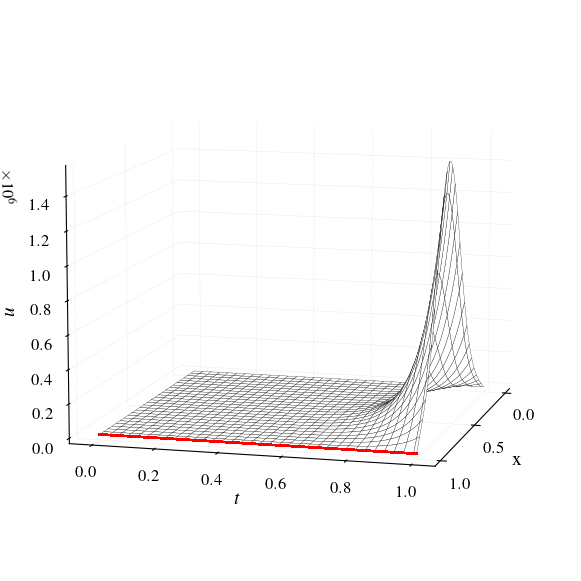

(<Figure size 2120.55x603.753 with 1 Axes>,
 <Axes3D: xlabel='x', ylabel='$t$', zlabel='$u$'>)

In [21]:
temporal = time_grid 
n_plot = 1000
plot_3d_response_draw_style(
    u_data=u_open[:n_plot, :],
    spatial=spatial,
    temporal=temporal[:n_plot],
    zlabel=r"$u$",
    title=None,
    filename="figs0529/u_open.jpg",
    rstride=30,
    cstride=4,
)

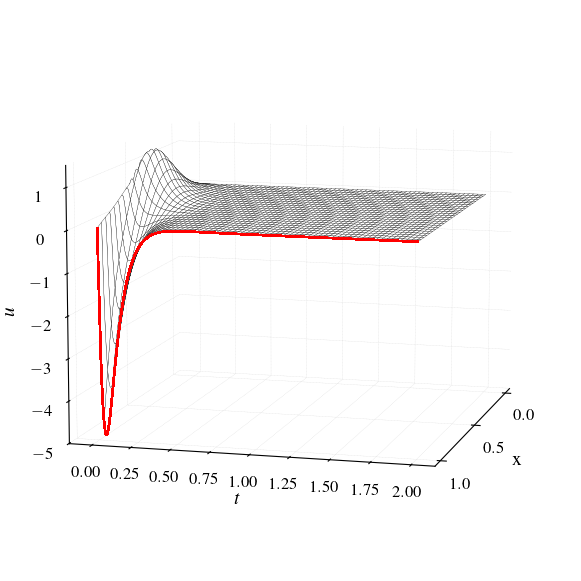

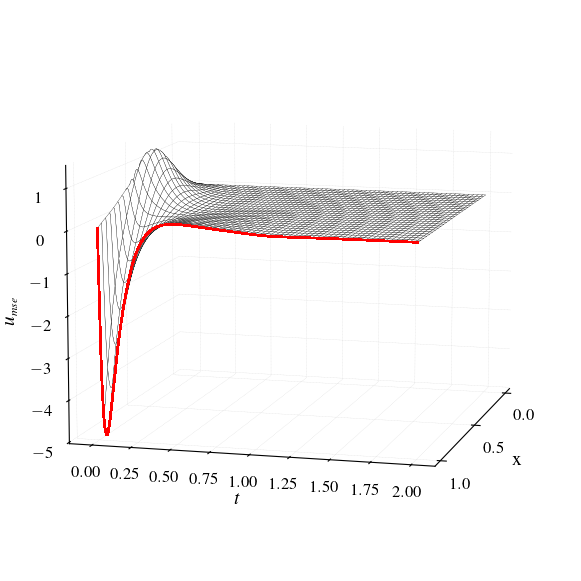

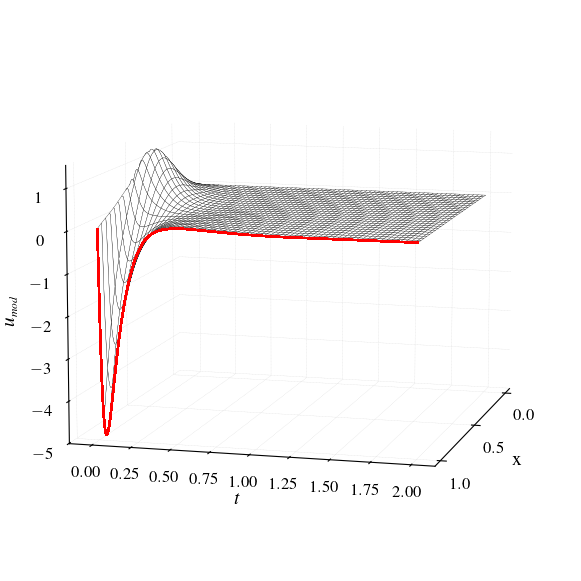

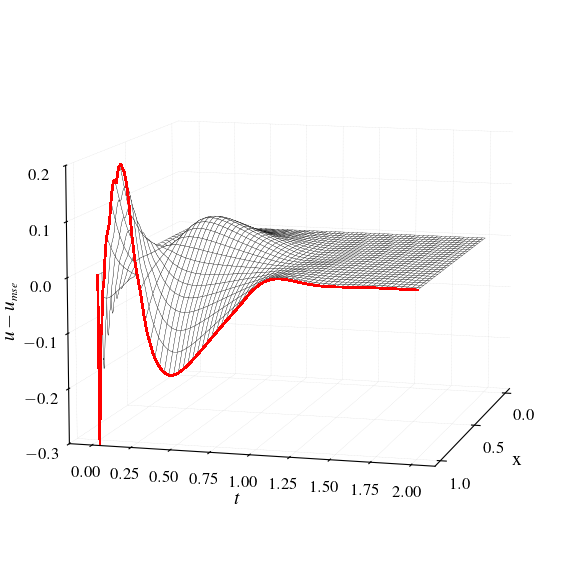

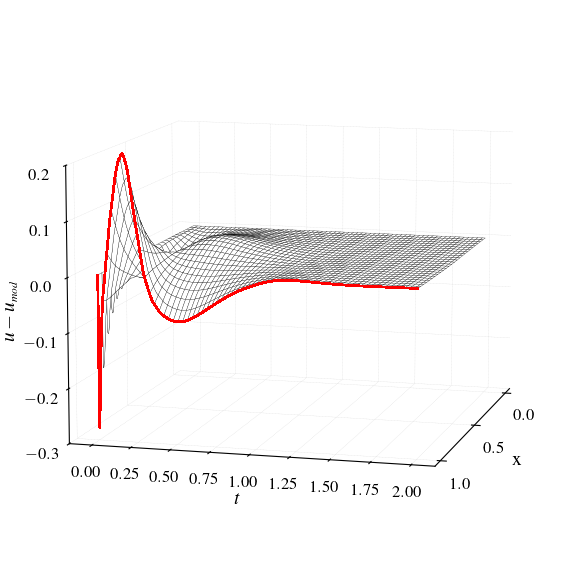

(<Figure size 2120.55x603.753 with 1 Axes>,
 <Axes3D: xlabel='x', ylabel='$t$', zlabel='$u-u_{\\scriptscriptstyle{mod}}$'>)

In [ ]:
temporal = time_grid

# plot_3d_response_draw_style(
#     u_data=u_open,
#     spatial=spatial,
#     temporal=temporal,
#     zlabel=r"$u$",
#     title=None,
#     filename="figs260511/u_open.jpg",
#     rstride=30,
#     cstride=4,
# )

plot_3d_response_draw_style(
    u_data=u_bs,
    spatial=spatial,
    temporal=temporal,
    zlabel=r"$u$",
    title=None,
    filename="figs/u_backstepping.jpg",
    rstride=30,
    cstride=4,
)

plot_3d_response_draw_style(
    u_data=u_nn_1,
    spatial=spatial,
    temporal=temporal,
    zlabel=r"${u}_{\scriptscriptstyle{mse}}$",
    title=None,
    filename="figs/u_nn_1.jpg",
    rstride=30,
    cstride=4,
)

plot_3d_response_draw_style(
    u_data=u_nn_2,
    spatial=spatial,
    temporal=temporal,
    zlabel=r"${u}_{\scriptscriptstyle{mod}}$",
    title=None,
    filename="figs/u_nn_2.jpg",
    rstride=30,
    cstride=4,
)

plot_3d_response_draw_style(
    u_data=u_diff_1,
    spatial=spatial,
    temporal=temporal,
    zlabel=r"$u-u_{\scriptscriptstyle{mse}}$",
    title=None,
    filename="figs/difference_bs_nn_1.jpg",
    rstride=30,
    cstride=4,
    zlim=(-0.3, 0.2)
)

plot_3d_response_draw_style(
    u_data=u_diff_2,
    spatial=spatial,
    temporal=temporal,
    zlabel=r"$u-u_{\scriptscriptstyle{mod}}$",
    title=None,
    filename="figs/difference_bs_nn_2.jpg",
    rstride=30,
    cstride=4,
    zlim=(-0.3, 0.2),
)

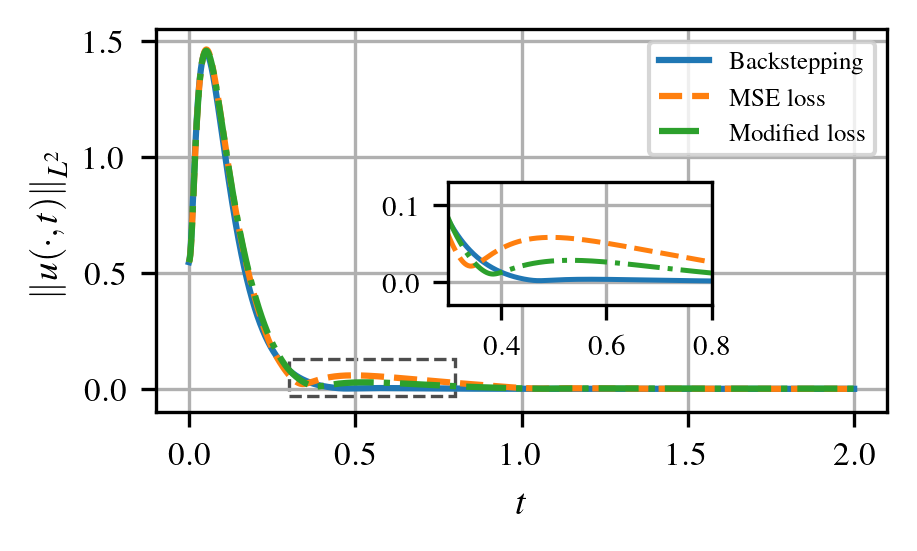

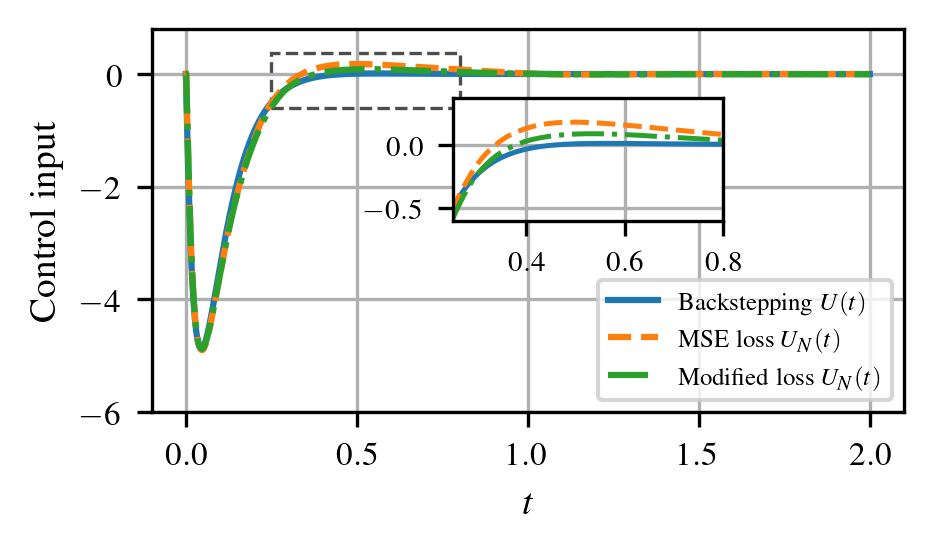

Relative L2 error of control: 0.08430352


In [24]:
plot_2d_draw_style_with_inset(
    x=temporal,
    ys=[l2_bs, l2_nn_1, l2_nn_2,],
    labels=["Backstepping", "MSE loss", "Modified loss",],
    linestyles=["-", "--", "-.",],
    ylim=(-0.1, 1.55),
    xlabel=r"$t$",
    ylabel=r"$\|u(\cdot,t)\|_{L^2}$",
    legend_loc="upper right",
    legend_fontsize=6,
    zoom_xlim=(0.3, 0.8),
    zoom_ylim=(-0.03, 0.13),
    inset_bbox=(0.4, 0.28, 0.36, 0.32),
    filename="figs0529/comp_L2.jpg",
)

plot_2d_draw_style_with_inset(
    x=temporal,
    ys=[U_bs, U_nn_1, U_nn_2],
    # labels=["Backstepping", "MSE loss", "Modified loss",],
    labels=[r"Backstepping $U(t)$", r"MSE loss $U_{\scriptscriptstyle{N}}(t)$", r"Modified loss $U_{\scriptscriptstyle{N}}(t)$",],
    linestyles=["-", "--", "-."],
    ylim=(-6, 0.8),
    xlabel=r"$t$",
    ylabel="Control input",
    legend_loc="lower right",
    zoom_xlim=(0.25, 0.8),
    zoom_ylim=(-0.6, 0.37),
    # zoom_ylim=None,
    inset_bbox=(0.4, 0.5, 0.36, 0.32),
    filename="figs0529/comp_U.jpg",
)

rel_err_U = np.linalg.norm(U_nn_1 - U_bs) / (np.linalg.norm(U_bs) + 1e-12)
print("Relative L2 error of control:", rel_err_U)

In [18]:
total_params = sum(p.numel() for p in model_2.parameters())
trainable_params = sum(p.numel() for p in model_2.parameters() if p.requires_grad)

print(f"Total parameters: {total_params}")
print(f"Trainable parameters: {trainable_params}")
print(model_2)

Total parameters: 237730
Trainable parameters: 237730
LambdaLSTMController(
  (lambda_encoder): LambdaEncoder(
    (deeponet): DeepONetCartesianProd(
      (branch): FNN(
        (linears): ModuleList(
          (0): Linear(in_features=101, out_features=256, bias=True)
          (1): Linear(in_features=256, out_features=256, bias=True)
          (2): Linear(in_features=256, out_features=128, bias=True)
        )
      )
      (trunk): FNN(
        (linears): ModuleList(
          (0): Linear(in_features=1, out_features=128, bias=True)
          (1): Linear(in_features=128, out_features=256, bias=True)
          (2): Linear(in_features=256, out_features=128, bias=True)
        )
      )
      (b): ParameterList(  (0): Parameter containing: [torch.float32 of size  (cuda:0)])
    )
    (embed): Sequential(
      (0): Linear(in_features=101, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=32, bias=True)
      (3): ReLU()
    )
  )
  (lstm): LS